# Cross-Paradigm Solvers Benchmark Visualization
## So sánh phương pháp giải SAT Solving với các phương pháp giải chính xác khác (ILP/MIP & CP)

Notebook trực quan hóa và so sánh hiệu năng thực tế giữa **3 trường phái giải chính xác lớn** trong Khoa học máy tính trên bài toán $N$-Queens:
1. **Boolean Satisfiability (SAT)**: Đại diện là `SAT (Product Encoding)` sử dụng solver CDCL Minisat22.
2. **Integer Linear Programming (ILP/MIP)**: Đại diện là `Gurobi Optimizer` và `IBM ILOG CPLEX MIP`.
3. **Constraint Programming (CP)**: Đại diện là `IBM ILOG CPLEX CP` và `Google OR-Tools CP-SAT`.

Dữ liệu được nạp trực tiếp từ file `solver_benchmark_results.csv` với đúng **17 kích thước bàn cờ** ($4 \times 4$ đến $1000 \times 1000$) đồng bộ với bài benchmark encoding.

In [1]:
import csv
import matplotlib.pyplot as plt

%matplotlib inline

CSV_FILE = "solver_benchmark_results.csv"
N_LIST = [4, 8, 9, 16, 25, 27, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
LABELS = [f"{n}x{n}" for n in N_LIST]
X_INDICES = list(range(len(N_LIST)))

SOLVER_NAMES = ["SAT (Product)", "CPLEX CP", "Gurobi (MIP)", "CPLEX MIP", "Google CP-SAT"]
data_by_n = {n: {} for n in N_LIST}

with open(CSV_FILE, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        if not row.get("N") or not row["N"].strip():
            continue
        n = int(row["N"])
        solver = row.get("Solver")
        if solver in SOLVER_NAMES and n in N_LIST:
            status = row.get("Status")
            t_str = row.get("Time_Seconds")
            if status == "SAT" and t_str is not None and t_str not in ("timeout", "-", ""):
                data_by_n[n][solver] = f"{float(t_str):.4f} s"
            else:
                data_by_n[n][solver] = "timeout"

print("[OK] Nạp dữ liệu thành công từ solver_benchmark_results.csv (17 kích thước)!")
print("=" * 94)
print("                    BẢNG TỔNG HỢP THỜI GIAN GIẢI CỦA 5 SOLVERS (17 KÍCH THƯỚC)")
print("=" * 94)
print(f"{'N':<6} | {'SAT (Product)':<13} | {'CPLEX CP':<12} | {'Gurobi (MIP)':<13} | {'CPLEX MIP':<13} | {'Google CP-SAT':<13}")
print("-" * 94)
for n in N_LIST:
    row_str = f"{n:<6} | "
    row_str += f"{data_by_n[n].get('SAT (Product)', '-'):<13} | "
    row_str += f"{data_by_n[n].get('CPLEX CP', '-'):<12} | "
    row_str += f"{data_by_n[n].get('Gurobi (MIP)', '-'):<13} | "
    row_str += f"{data_by_n[n].get('CPLEX MIP', '-'):<13} | "
    row_str += f"{data_by_n[n].get('Google CP-SAT', '-'):<13}"
    print(row_str)
print("=" * 94)

[OK] Nạp dữ liệu thành công từ solver_benchmark_results.csv (17 kích thước)!
                    BẢNG TỔNG HỢP THỜI GIAN GIẢI CỦA 5 SOLVERS (17 KÍCH THƯỚC)
N      | SAT (Product) | CPLEX CP     | Gurobi (MIP)  | CPLEX MIP     | Google CP-SAT
----------------------------------------------------------------------------------------------
4      | 0.0003 s      | 0.0349 s     | 0.0094 s      | 0.0182 s      | 0.0207 s     
8      | 0.0008 s      | 0.0323 s     | 0.0082 s      | 0.0116 s      | 0.0139 s     
9      | 0.0015 s      | 0.0309 s     | 0.0086 s      | 0.0117 s      | 0.0216 s     
16     | 0.0036 s      | 0.0298 s     | 0.0413 s      | 0.0167 s      | 0.0224 s     
25     | 0.0077 s      | 0.0332 s     | 0.0144 s      | 0.0256 s      | 0.0634 s     
27     | 0.0128 s      | 0.0312 s     | 0.0316 s      | 0.0269 s      | 0.0647 s     
36     | 0.0167 s      | 0.0329 s     | 0.0686 s      | 0.0398 s      | 0.0941 s     
49     | 0.0388 s      | 0.0328 s     | 0.0394 s      | 0.078

## Biểu đồ so sánh thời gian thực thi của các Solvers (Linear Scale)
Biểu đồ thể hiện thời gian giải thực tế trên **thang đo tuyến tính 100% (Linear Scale)** cho cả 17 kích thước bàn cờ ($4 \times 4$ đến $1000 \times 1000$).

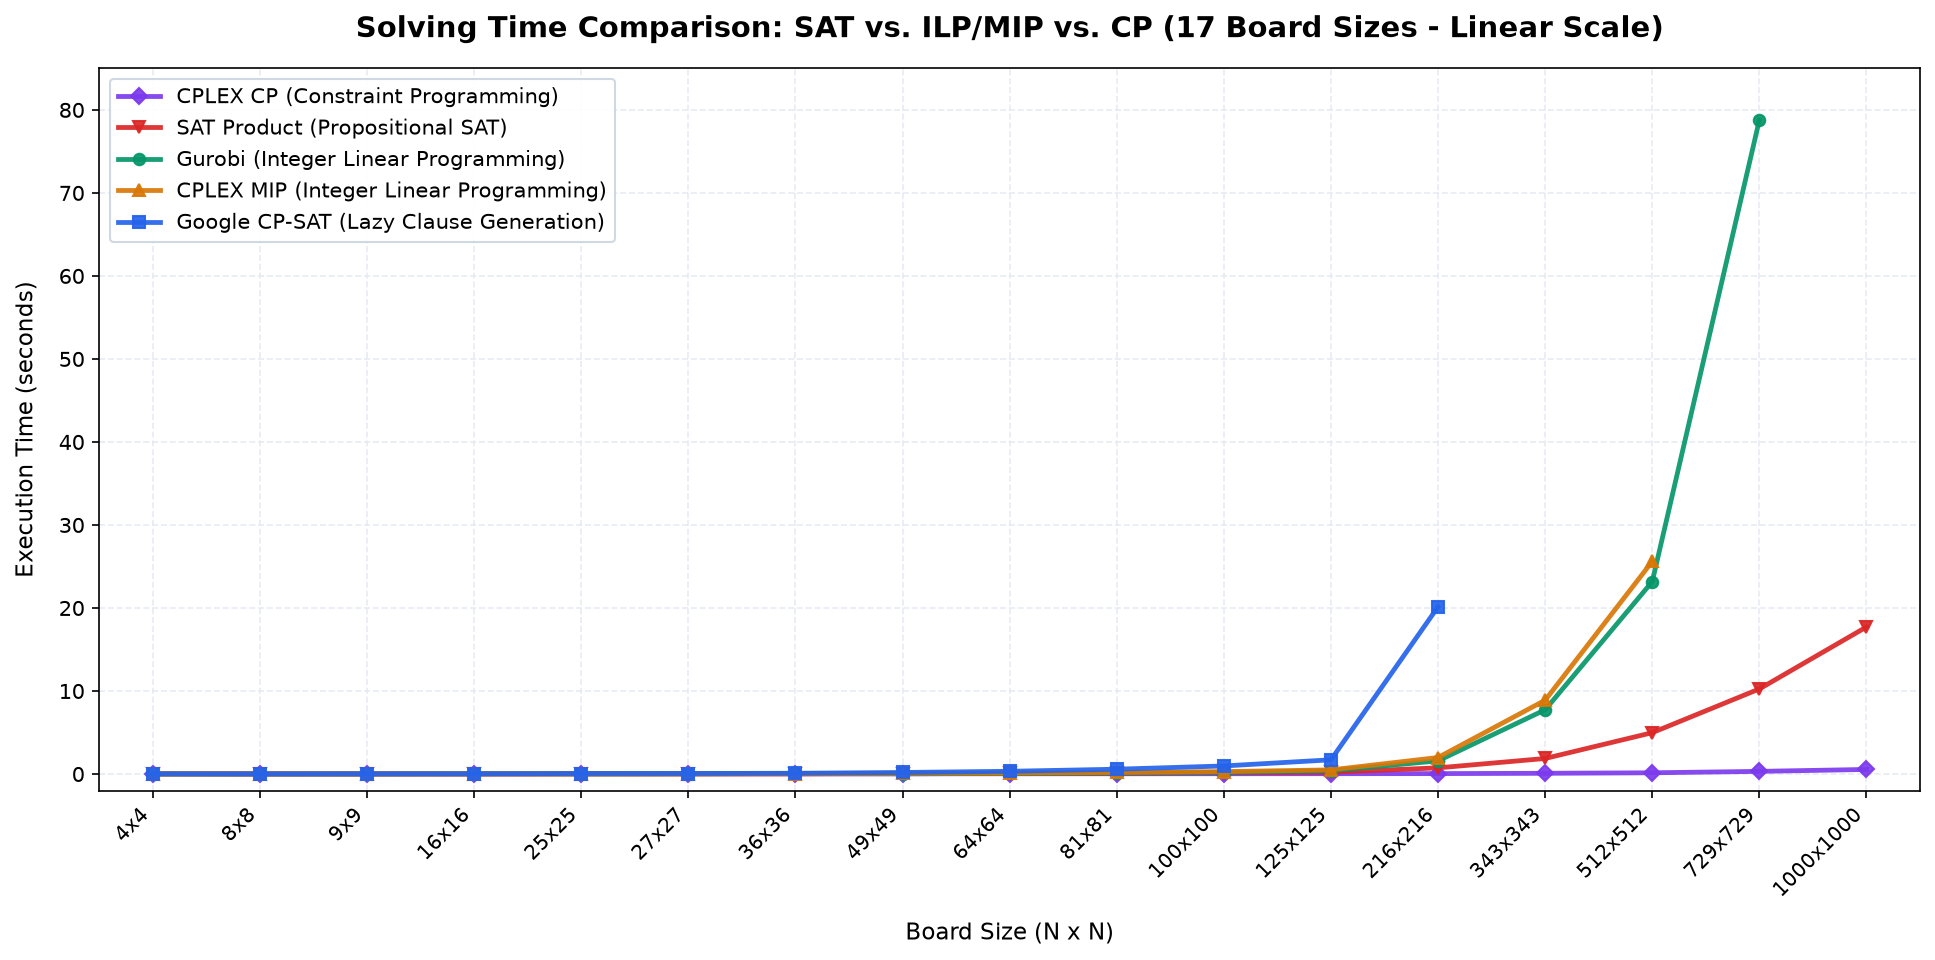

In [2]:
SOLVER_STYLES = {
    "CPLEX CP": {"color": "#7C3AED", "marker": "D", "name": "CPLEX CP (Constraint Programming)"},
    "SAT (Product)": {"color": "#DC2626", "marker": "v", "name": "SAT Product (Propositional SAT)"},
    "Gurobi (MIP)": {"color": "#059669", "marker": "o", "name": "Gurobi (Integer Linear Programming)"},
    "CPLEX MIP": {"color": "#D97706", "marker": "^", "name": "CPLEX MIP (Integer Linear Programming)"},
    "Google CP-SAT": {"color": "#2563EB", "marker": "s", "name": "Google CP-SAT (Lazy Clause Generation)"}
}

solver_pts = {s: {"x": [], "y": []} for s in SOLVER_STYLES}

with open(CSV_FILE, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        if not row.get("N") or not row["N"].strip():
            continue
        n = int(row["N"])
        s = row.get("Solver")
        if s in solver_pts and n in N_LIST:
            idx = N_LIST.index(n)
            t_str = row.get("Time_Seconds")
            if row.get("Status") == "SAT" and t_str is not None and t_str not in ("timeout", "-", ""):
                solver_pts[s]["x"].append(idx)
                solver_pts[s]["y"].append(float(t_str))

plt.figure(figsize=(13, 6.5), dpi=150)
for s, style in SOLVER_STYLES.items():
    plt.plot(solver_pts[s]["x"], solver_pts[s]["y"], 
             label=style["name"], color=style["color"], marker=style["marker"], 
             markersize=5.5, linewidth=2.3, alpha=0.92)

plt.title("Solving Time Comparison: SAT vs. ILP/MIP vs. CP (17 Board Sizes - Linear Scale)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Board Size (N x N)", fontsize=11, labelpad=10)
plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=10)
plt.xticks(X_INDICES, LABELS, rotation=45, ha="right", fontsize=9.5)
plt.xlim(-0.5, len(N_LIST) - 0.5)
plt.ylim(-2, 85)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, linestyle="--", color="#E2E8F0", alpha=0.8)
plt.legend(frameon=True, facecolor="white", framealpha=0.92, edgecolor="#CBD5E1", fontsize=10, loc="upper left")
plt.tight_layout()
plt.show()

### Phân tích học thuật chuyên sâu (Cross-Paradigm Comparison):

1. **CPLEX CP (Constraint Programming) - Đứng đầu về khả năng mở rộng (Scalability)**:
   - Giải $1000 \times 1000$ chỉ mất vỏn vẹn **0.55 giây**!
   - Nhờ mô hình chỉ cần đúng $N$ biến số nguyên và $3$ ràng buộc toàn cục `AllDifferent` kết hợp giải thuật lọc Regin (Matching trên đồ thị hai phía), CPLEX CP loại trừ xung đột miền giá trị tức thời mà không phải rẽ nhánh hay sinh mệnh đề phụ.

2. **SAT (Product Encoding) - Tốc độ xuất sắc ở bài toán tìm nghiệm khả thi**:
   - Giải thành công đến $1000 \times 1000$ trong **17.7 giây**, nhanh hơn và mở rộng tốt hơn toàn bộ các solver MIP thương mại (Gurobi timeout ở $N=1000$, CPLEX MIP timeout ở $N=729$).
   - Khẳng định ưu thế của động cơ CDCL: Với bài toán thuần tìm nghiệm thỏa mãn (feasibility), SAT giải trực tiếp trên cấu trúc logic nhanh hơn nhiều so với việc giải bài toán liên tục LP của MIP.

3. **MIP (Gurobi & CPLEX MIP) - Giới hạn khi số biến nguyên nhị phân tăng vọt**:
   - Với $N=729$ và $N=1000$, số biến nhị phân lên tới từ $531,441$ đến $1,000,000$ biến $x_{i,j}$. Chi phí xây dựng ma trận ràng buộc và giải Simplex liên tục tại các nút nhánh khiến MIP bị timeout (> 100s).

4. **Google OR-Tools CP-SAT - Cơ chế Lazy Clause Generation**:
   - Hoạt động cực kỳ ổn định ở các quy mô vừa ($N \le 216$), nhưng ở quy mô lớn ($N \ge 343$) cơ chế tạo mệnh đề giải thích xung đột (explanation clauses) tích lũy khiến solver đạt ngưỡng timeout 100s.